# Практическая работа 1B

Фильтрация изображений с использованием свёртки в Python

## Задание 1

Применить ко всем растрам из папки «Изображения» фильтры высоких и низких частот. Сохранить обработанные изображения.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.parse import quote
from urllib.request import urlopen
from zipfile import ZipFile
import tempfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

workdir = tempfile.TemporaryDirectory()
folder = Path(workdir.name)
source = folder / 'images'
results = folder / 'results'
source.mkdir()
results.mkdir()
course_folder = '1. Фильтрация изображений с использованием свертки в Python'
url = ('https://raw.githubusercontent.com/Alexandre77777/image_processing/main/'
       + quote(course_folder + '/Изображения.zip', safe='/'))
with urlopen(url, timeout=60) as response:
    archive_data = response.read()
with ZipFile(BytesIO(archive_data)) as archive:
    for item in archive.infolist():
        name = Path(item.filename).name
        if Path(name).suffix.lower() in ('.jpg', '.jpeg', '.png'):
            (source / name).write_bytes(archive.read(item))
paths = sorted(source.iterdir())
if len(paths) != 5:
    raise ValueError('В архиве должны быть пять изображений')

mean_kernel = np.ones((5, 5), dtype=np.float32) / 25
laplace_kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], dtype=np.float32)
sharp_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
horizontal_kernel = np.array([[-1, -1], [2, 2], [-1, -1]], dtype=np.float32)
diagonal_kernel = np.array([[-2, -1, 0], [-1, 0, 1], [0, 1, 2]], dtype=np.float32) / 4
filters = [
    ('mean', mean_kernel, False, 1),
    ('laplace', laplace_kernel, True, 1),
    ('sharp', sharp_kernel, False, 1),
    ('horizontal', horizontal_kernel, True, 1),
    ('diagonal', diagonal_kernel, True, 2),
]

for path in paths:
    image = cv2.imread(str(path))
    for name, kernel, absolute, gain in filters:
        response = cv2.filter2D(image, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT_101)
        if absolute:
            result = cv2.convertScaleAbs(response, alpha=gain)
        else:
            result = np.clip(np.round(response * gain), 0, 255).astype(np.uint8)
        cv2.imwrite(str(results / f'{path.stem}_{name}.png'), result)

## Задание 2

Сравнить полученные изображения с исходными и составить описание (до-после). Указать, какие классы объектов стали наиболее ярко выражены. Сделать общий вывод о том, для каких целей лучше всего использовать фильтры высоких и низких частот.

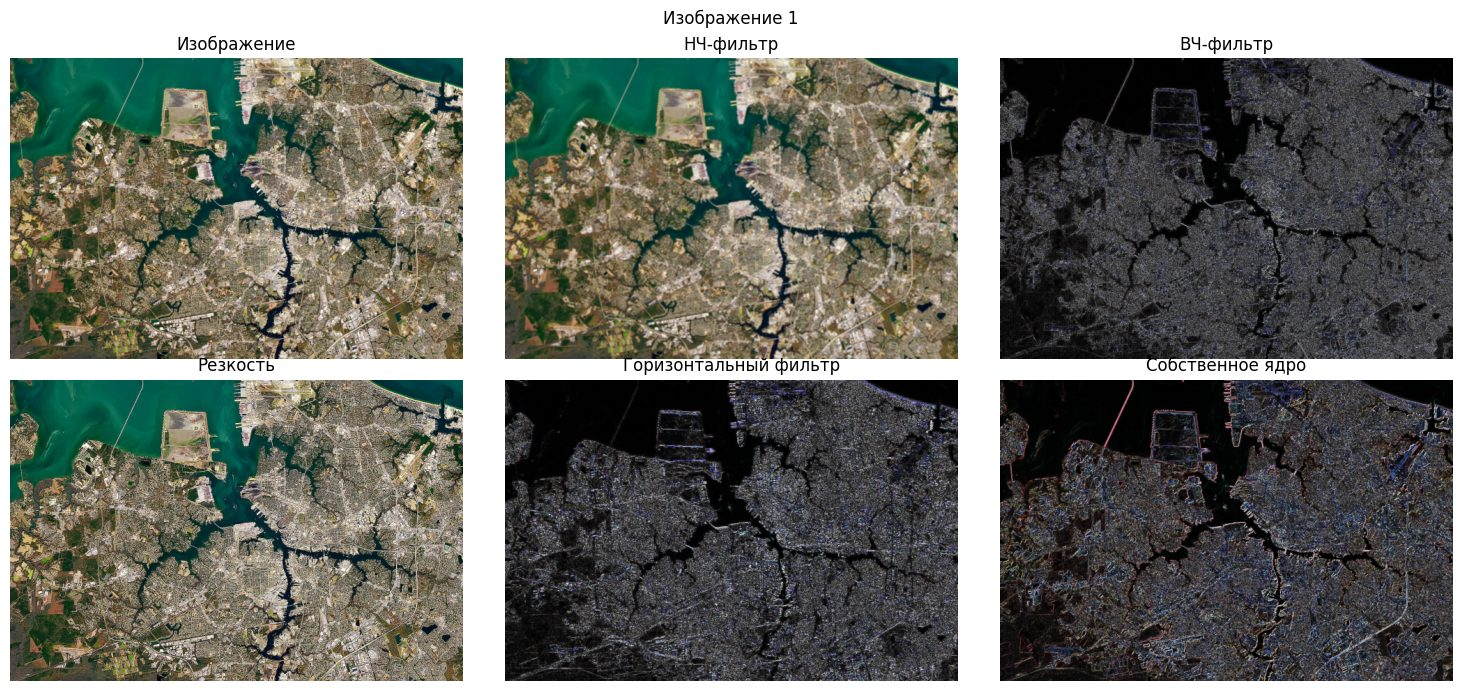

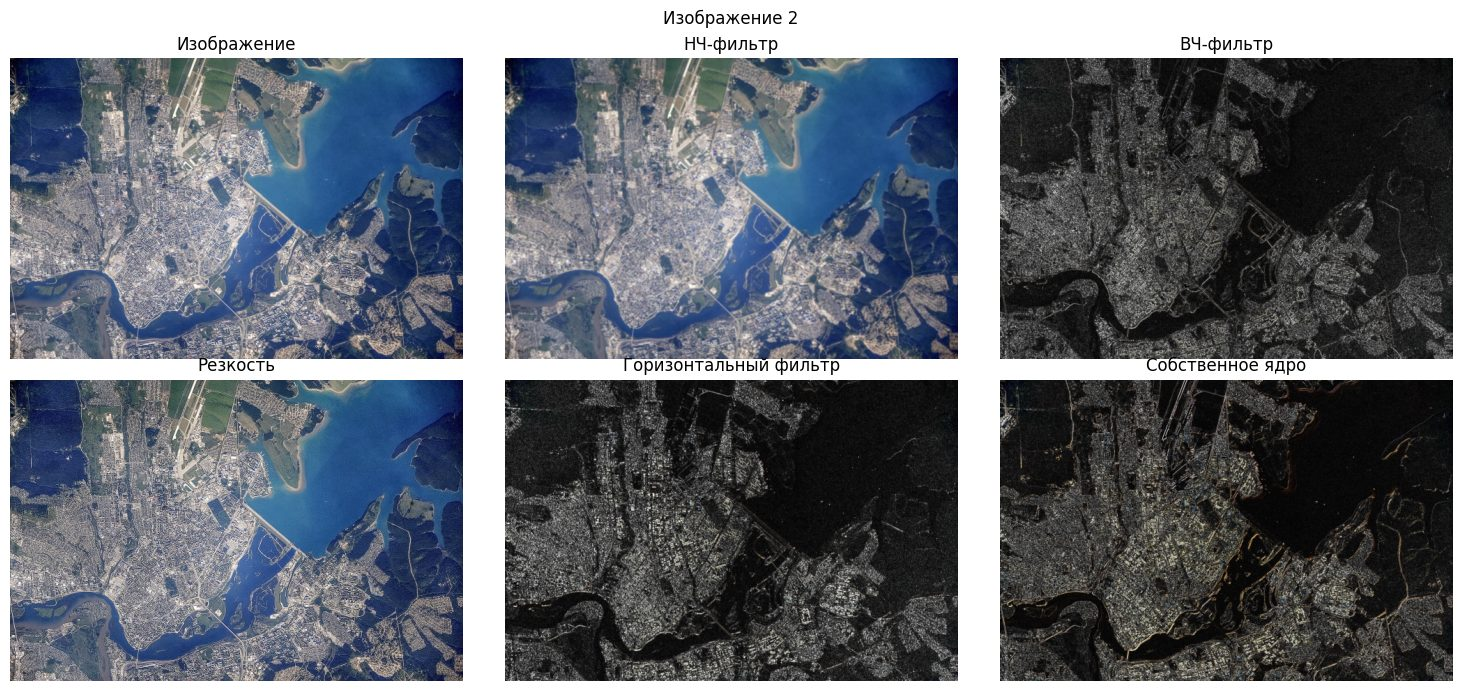

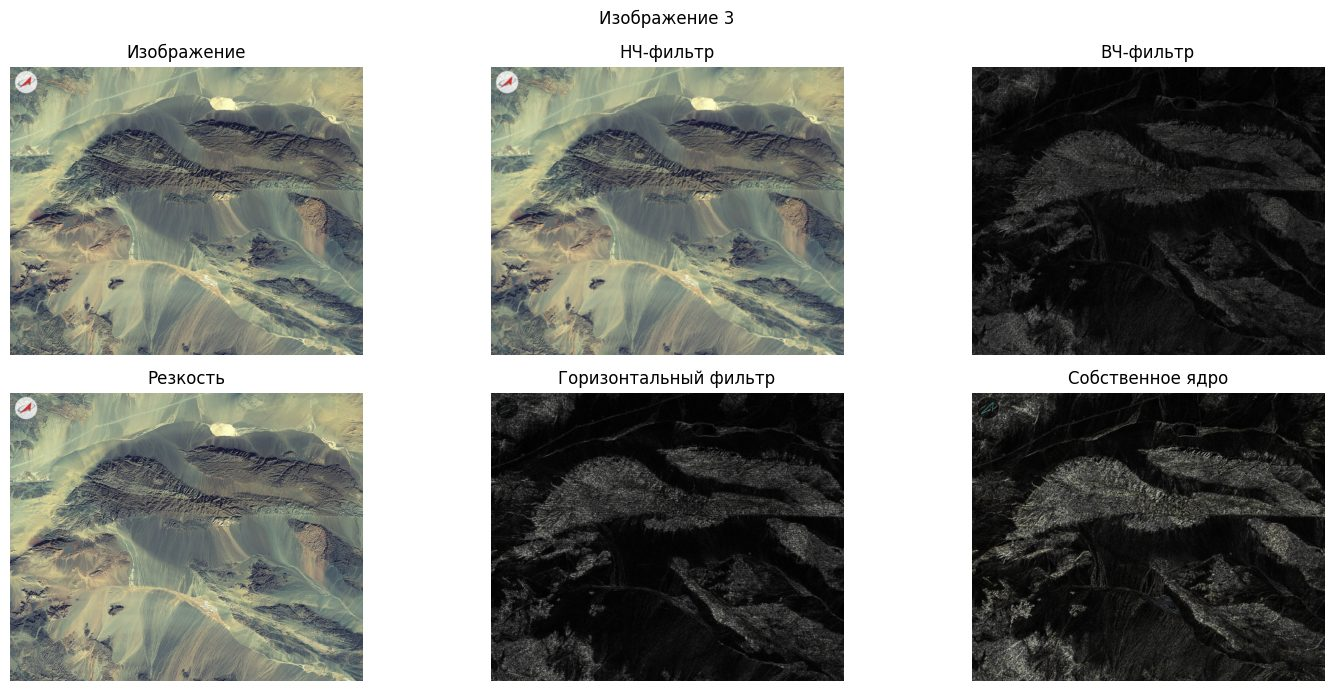

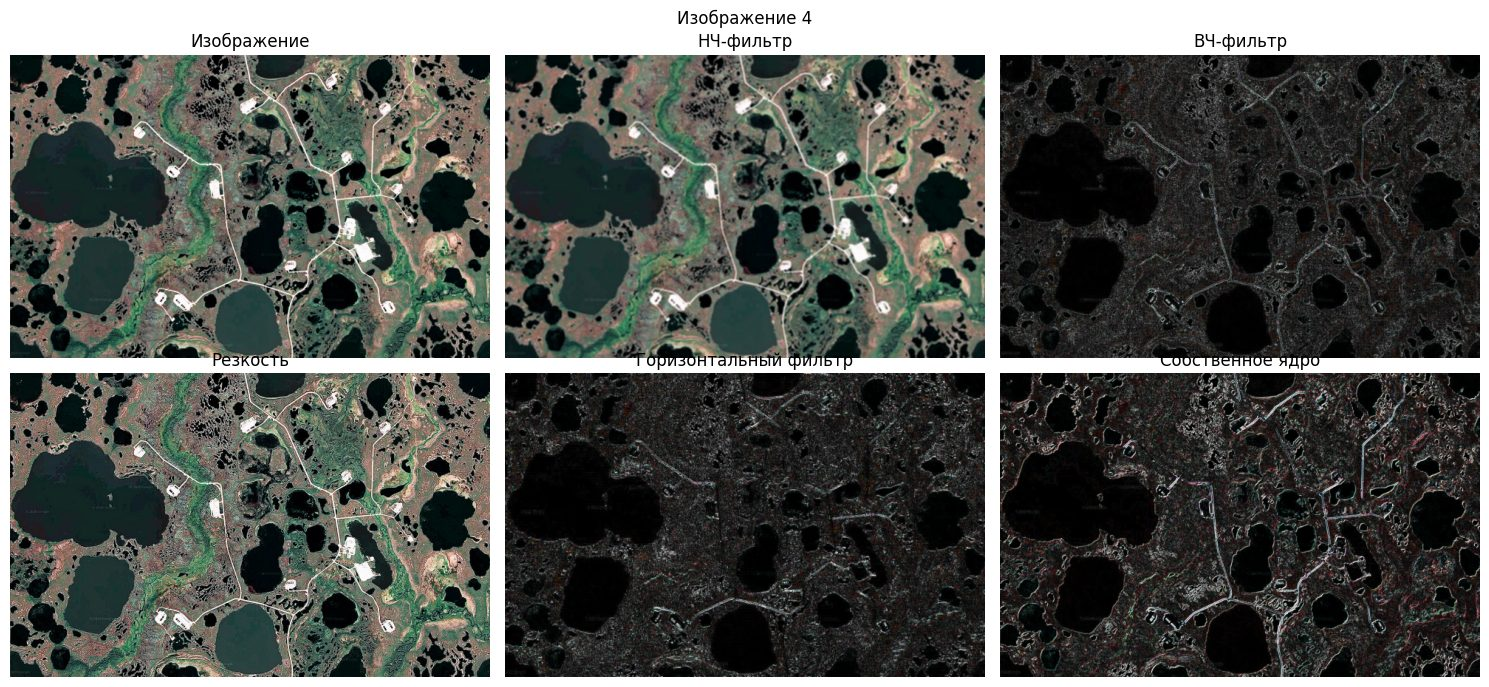

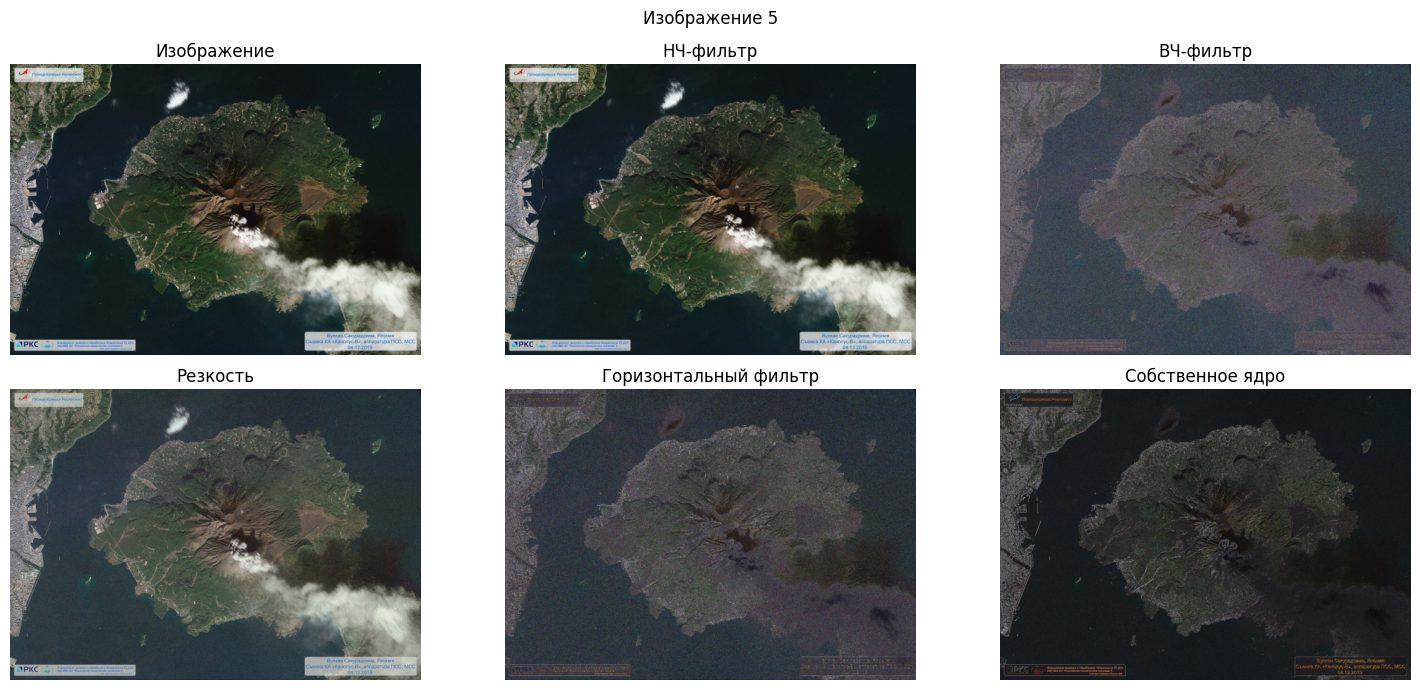

In [2]:
titles = ['Изображение', 'НЧ-фильтр', 'ВЧ-фильтр',
          'Резкость', 'Горизонтальный фильтр', 'Собственное ядро']
for number, path in enumerate(paths, 1):
    images = [cv2.imread(str(path))]
    for name, _, _, _ in filters:
        images.append(cv2.imread(str(results / f'{path.stem}_{name}.png')))
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    fig.suptitle(f'Изображение {number}')
    for ax, title, image in zip(axes.flat, titles, images):
        h, w = image.shape[:2]
        scale = min(1, 650 / max(h, w))
        small = cv2.resize(image, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
        ax.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

1. Усреднение сгладило мелкую застройку. ВЧ-фильтр выделяет береговую линию, дороги и границы кварталов.
2. После сглаживания мелкие здания стали менее различимыми. ВЧ-фильтр подчёркивает берега и причалы.
3. НЧ-фильтр сгладил мелкие борозды. ВЧ-фильтр усиливает границы светлых и затенённых склонов.
4. При сглаживании берега озёр стали мягче. На ВЧ-фильтре лучше видны контуры озёр и дороги.
5. Усреднение уменьшило фактуру склонов и облаков. ВЧ-фильтр выделяет берег, края облаков и резкие переходы рельефа.

НЧ-фильтр подходит для сглаживания шума и мелкой фактуры, но размывает небольшие объекты.
ВЧ-фильтр помогает выделять границы объектов. Повышение резкости усиливает детали вместе с шумом.

## Задание 3

Определить свои параметры ядра и указать, для каких целей его можно использовать. Привести примеры.

Его можно использовать для подчёркивания диагональных участков дорог и складок рельефа.

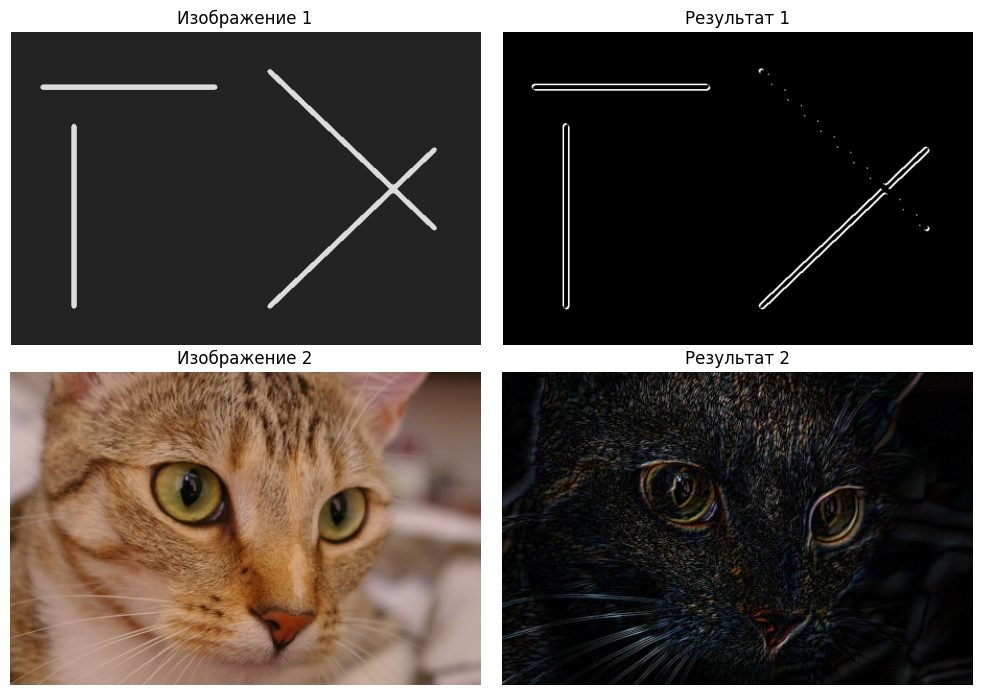

In [3]:
from skimage import data

pattern = np.full((400, 600, 3), 35, dtype=np.uint8)
cv2.line(pattern, (40, 70), (260, 70), (220, 220, 220), 5)
cv2.line(pattern, (80, 120), (80, 350), (220, 220, 220), 5)
cv2.line(pattern, (330, 50), (540, 250), (220, 220, 220), 5)
cv2.line(pattern, (330, 350), (540, 150), (220, 220, 220), 5)
photo = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR)
outputs = []
for image in [pattern, photo]:
    response = cv2.filter2D(image, cv2.CV_32F, diagonal_kernel, borderType=cv2.BORDER_REFLECT_101)
    outputs.append(cv2.convertScaleAbs(response, alpha=2))

fig, axes = plt.subplots(2, 2, figsize=(10, 7.0), squeeze=False)
for ax, (title, image) in zip(axes.flat, [('Изображение 1', pattern),
        ('Результат 1', outputs[0]),
        ('Изображение 2', photo),
        ('Результат 2', outputs[1])]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
for ax in list(axes.flat)[4:]:
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)